# Advertising A/B Test

The goal of this project is to find out whether showing users an advertisement leads to more conversions than showing them a public service announcement (PSA).

- **Control:** PSA
- **Treatment:** Advertisement
- **Primary metric:** Conversion rate

[Dataset source: Kaggle](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing)

Download `marketing_AB.csv` and place it in the same folder as this notebook before running the analysis.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

## 1. Data preparation

First, I check the dataset for missing values, duplicate users, and unexpected experiment groups.

In [2]:
df = pd.read_csv('marketing_AB.csv')

df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

df.head()

,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


In [3]:
df.info()
print('Missing values:')
print(df.isna().sum())
print('Duplicate user IDs:', df['user_id'].duplicated().sum())
print('Experiment groups:', df['test_group'].unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   user_id        588101 non-null  int64 
 1   test_group     588101 non-null  object
 2   converted      588101 non-null  bool  
 3   total_ads      588101 non-null  int64 
 4   most_ads_day   588101 non-null  object
 5   most_ads_hour  588101 non-null  int64 
dtypes: bool(1), int64(3), object(2)
memory usage: 23.0+ MB
Missing values:
user_id          0
test_group       0
converted        0
total_ads        0
most_ads_day     0
most_ads_hour    0
dtype: int64
Duplicate user IDs: 0
Experiment groups: ['ad' 'psa']


In [4]:
# Make sure each user appears once and has a valid conversion outcome
assert not df[['user_id', 'test_group', 'converted']].isna().any().any()
assert not df['user_id'].duplicated().any()
assert set(df['test_group']) == {'ad', 'psa'}

df['converted'] = df['converted'].astype(str).str.lower().map({
    'true': 1, 'false': 0, '1': 1, '0': 0})
assert df['converted'].notna().all()

## 2. Conversion rates

Conversion rate is the percentage of users who converted in each experiment group. I also check how users are distributed between the groups.

In [5]:
summary = df.groupby('test_group')['converted'].agg(
    users='count',
    conversions='sum'
)
summary['conversion_rate'] = summary['conversions'] / summary['users']
summary['allocation_pct'] = summary['users'] / summary['users'].sum() * 100
summary

,users,conversions,conversion_rate,allocation_pct
test_group,,,,
ad,564577,14423,0.025547,96.000007
psa,23524,420,0.017854,3.999993


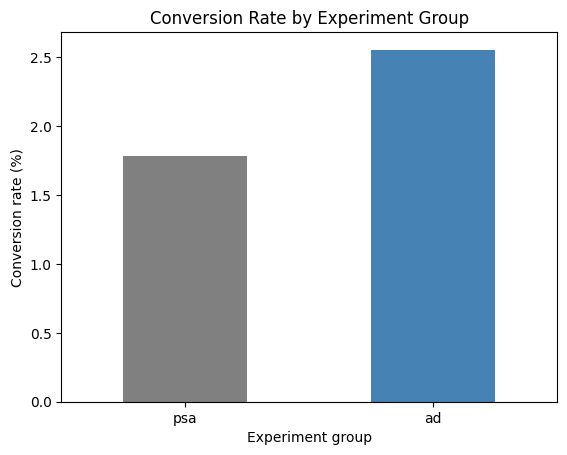

In [6]:
(summary.loc[['psa', 'ad'], 'conversion_rate'] * 100).plot(
    kind='bar', color=['gray', 'steelblue'], rot=0)
plt.title('Conversion Rate by Experiment Group')
plt.xlabel('Experiment group')
plt.ylabel('Conversion rate (%)')
plt.show()

The groups are unequal in size. This is not necessarily an issue if the experiment was designed that way. The intended allocation is not provided, so I cannot confirm whether the observed split matches the original experiment design.

## 3. Hypothesis testing

I use a two-proportion Z-test to determine whether the difference in conversion rates is statistically significant.

- **Null hypothesis (H₀):** Both groups have the same conversion rate.
- **Alternative hypothesis (H₁):** The conversion rates are different.
- **Significance level:** 0.05

In [7]:
ad = summary.loc['ad']
psa = summary.loc['psa']

z_stat, p_value = proportions_ztest(
    [ad['conversions'], psa['conversions']],
    [ad['users'], psa['users']])

print(f'Z-statistic: {z_stat:.4f}')
print(f'P-value: {p_value:.3e}')

if p_value < 0.05:
    print('Reject the null hypothesis.')
else:
    print('Fail to reject the null hypothesis.')

Z-statistic: 7.3701
P-value: 1.705e-13
Reject the null hypothesis.


## 4. Conversion lift and confidence interval

Statistical significance alone does not tell us whether the improvement is meaningful. I calculate the absolute lift, relative lift, and a 95% confidence interval for the difference in conversion rates.

In [8]:
absolute_lift = ad['conversion_rate'] - psa['conversion_rate']
relative_lift = absolute_lift / psa['conversion_rate']

ci_low, ci_high = confint_proportions_2indep(
    int(ad['conversions']), int(ad['users']),
    int(psa['conversions']), int(psa['users']),
    method='newcomb', alpha=0.05)

print(f'Absolute lift: {absolute_lift * 100:.3f} percentage points')
print(f'Relative lift: {relative_lift:.2%}')
print(f'95% confidence interval: [{ci_low * 100:.3f}, {ci_high * 100:.3f}] pp')

Absolute lift: 0.769 percentage points
Relative lift: 43.09%
95% confidence interval: [0.587, 0.936] pp


## 5. Ad exposure (exploratory analysis)

I look at how conversion rates vary with the number of impressions in the advertisement group. This may help identify questions for a follow-up experiment, but it does not prove that showing more ads causes more conversions.

In [9]:
ad_users = df[df['test_group'] == 'ad'].copy()

ad_users['exposure_group'] = pd.cut(
    ad_users['total_ads'],
    bins=[-1, 5, 10, 20, 50, 100, float('inf')],
    labels=['0-5', '6-10', '11-20', '21-50', '51-100', '101+'])

exposure = ad_users.groupby('exposure_group', observed=True)['converted'].agg(
    users='count', conversion_rate='mean')
exposure

,users,conversion_rate
exposure_group,,
0-5,169962,0.002512
6-10,79537,0.004853
11-20,123334,0.008400
21-50,125541,0.029154
51-100,44149,0.116311
101+,22054,0.171352


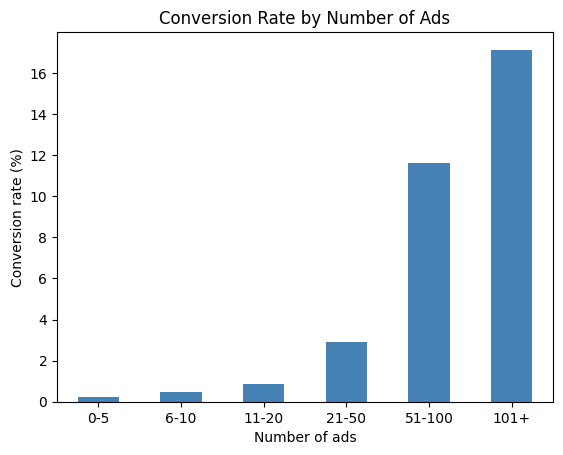

In [10]:
(exposure['conversion_rate'] * 100).plot(kind='bar', color='steelblue', rot=0)
plt.title('Conversion Rate by Number of Ads')
plt.xlabel('Number of ads')
plt.ylabel('Conversion rate (%)')
plt.show()

## 6. Business impact

I estimate how many additional conversions the advertisement generated compared with showing PSAs to the same number of users, assuming valid randomized assignment.

In [11]:
incremental_conversions = ad['users'] * absolute_lift

print(f'Estimated incremental conversions: {incremental_conversions:,.0f}')
print(f'Additional conversions per 100,000 users: {100000 * absolute_lift:,.0f}')

Estimated incremental conversions: 4,343
Additional conversions per 100,000 users: 769


Since advertising costs and revenue are not available, I use a hypothetical contribution margin of $50 per additional conversion to estimate how much the company could spend per user before losing money.

In [12]:
margin_per_conversion = 50  # Example assumption, not actual revenue
break_even_cost = absolute_lift * margin_per_conversion

print(f'Break-even incremental advertising cost per user: ${break_even_cost:.2f}')

Break-even incremental advertising cost per user: $0.38


## 7. Conclusion and recommendation

The advertisement group achieved a conversion rate of 2.55%, compared to 1.79% for the control group, representing a 43.09% relative increase. The hypothesis test confirmed that this difference was statistically significant, with an estimated 4,343 incremental conversions, assuming valid experiment assignment.

Based on these findings, I recommend a phased rollout of the advertising campaign, provided that the additional revenue generated outweighs advertising costs.


